# (2) Example_MNIST_CNN_Load

Questo notebook contiene un esempio su come caricare una Convolutional Neural Network (CNN) giá allenarla per poterla poi usare per _inferenza_.

## 1. Setup and Imports

Importiamo le librarie che ci serviranno

In [1]:
# Importazione delle librerie fondamentali per il calcolo tensoriale e la gestione della rete neurale.
# L'ambiente delle dipendenze deve essere speculare a quello utilizzato durante la fase di addestramento.
import numpy as np
import matplotlib.pyplot as plt
import torch
from torchvision import datasets, transforms
from tqdm import tqdm

## 2. Data Preparation

Come per l'allenamento, é necessario avere accesso al dataset (e.g. MNIST) per fornirlo in ingresso alla rete.

In [2]:
# Inizializzazione, download (se mancante in locale) e partizionamento del dataset MNIST.

# Inference batch size
batch_size = 64

# Load the MNIST training set
mnist_data = datasets.MNIST("./", download=True, train=True,
                              transform=transforms.Compose([
                                transforms.ToTensor(),
                                transforms.Normalize((0.1307,), (0.3081,))  
                                ]),
                              target_transform=transforms.Compose([
                                lambda x:torch.tensor([x]), 
                                lambda x:torch.nn.functional.one_hot(x,10).float(),
                                lambda x:x.squeeze(),
                                ]))

# Load the MNIST test set
mnist_test = datasets.MNIST("./", download=True, train=False,
                              transform=transforms.Compose([
                                transforms.ToTensor(),
                                transforms.Normalize((0.1307,), (0.3081,))  
                                ]),
                              target_transform=transforms.Compose([
                                lambda x:torch.tensor([x]), 
                                lambda x:torch.nn.functional.one_hot(x,10).float(),
                                lambda x:x.squeeze(),
                                ]))

# Anche se il modello non deve più studiare, l'istanza del DataLoader per il subset di Test 
# è strettamente necessaria per fornire i dati in ingresso durante la successiva fase di inferenza.

# Split dataset into training and validation and create data loaders
ds_train, ds_val = torch.utils.data.random_split(mnist_data, [0.8, 0.2])
mnist_loader_train = torch.utils.data.DataLoader(ds_train, batch_size=batch_size, shuffle=True)
mnist_loader_val = torch.utils.data.DataLoader(ds_val, batch_size=batch_size, shuffle=False)

# Create test set loader
mnist_loader_test = torch.utils.data.DataLoader(mnist_test, batch_size=batch_size, shuffle=False)
N_test = len(mnist_loader_test.dataset)

## 3. Define the CNN Model

Se abbiamo una rete giá allenata, quello che é stato salvato sono i valori di tutte le variabili interne alla rete. Dobbiamo comunque definire nel nostro nuovo script o notebook la struttura della rete in modo che quando le variabili vengono caricate il compilatore Python sappia dove a cosa corrisponde ogni variabile. Nel seguito quindi la stessa ddefinizione di rete CNN che abbiamo usato nel training.

In [3]:
# Definizione della topologia della Rete Neurale Convoluzionale (CNN).
# È imperativo che l'architettura dichiarata in questa sede sia strutturalmente identica 
# a quella del modello originale, per consentire la perfetta mappatura dei pesi pre-addestrati.

# Define the CNN topology
def mnist_cnn():
    return torch.nn.Sequential(
        torch.nn.Conv2d(1, 8, 3, padding='valid', stride=2),
        torch.nn.ReLU(),
        torch.nn.Conv2d(8, 16, 3, padding='valid', stride=2),
        torch.nn.ReLU(),
        torch.nn.Flatten(),
        torch.nn.Linear(576, 16),
        torch.nn.ReLU(),
        torch.nn.Linear(16, 10)
        )

## 4. Training and Testing Functions

Anche se non ci serve piú esplicitamente per il training, il Wrapper che avevamo definito coniente anche un'interfaccia per il testing. É quindi conveniente e coerente ri-definirlo.
Ribadiamo che la definizione di una funzione Wrapper, per quanto non rara, non é di per sé uno standard nell'allenamento di reti in Pytorch. Resta comunque vantaggioso per poter poi utilizzare il framework Cross-Sim per In-Memory Computing.

In [4]:
# Istanziazione della classe "Wrapper" architetturale.
# Sebbene la fase di training venga totalmente bypassata, questa classe espone i metodi di "forward"
# necessari per propagare l'ingresso nella rete durante l'inferenza. Inoltre, mantiene la 
# standardizzazione necessaria per l'interfacciamento con Cross-Sim nel notebook successivo.

# Wrapper for training the CNN
class SequentialWrapper():
    def __init__(self, net, loss, learning_rate=1e-3):
        self.net = net
        self.loss = loss
        self.learning_rate = learning_rate
        self.optimizer = torch.optim.Adam(self.net.parameters(), lr=self.learning_rate)

    def forward(self, x):
        return self.net(x)
    
    def training_step(self, batch):
        self.optimizer.zero_grad()
        pred = self.forward(batch[0])
        loss = self.loss(pred, batch[1])
        loss.backward()
        self.optimizer.step()
        return loss

    def validation_step(self, batch):
        pred = self.forward(batch[0])
        loss = self.loss(pred, batch[1])
        return loss
    
    def train_epoch(self, train_loader, val_loader):
        loss_train, loss_val = 0, 0
        for minibatch in iter(train_loader):
            loss_train += self.training_step(minibatch).detach()
        for minibatch in iter(val_loader):
            loss_val += self.validation_step(minibatch).detach()
        return loss_train/len(train_loader), loss_val/len(val_loader)
    
    def train(self, train_loader, val_loader, epochs):
        loss_train, loss_val = np.zeros(epochs), np.zeros(epochs)
        for e in tqdm(range(0, epochs)):
            lt, lv = self.train_epoch(train_loader, val_loader)
            loss_train[e] = lt
            loss_val[e] = lv
        return loss_train, loss_val

# Create the wrapped PyTorch model
mnist_cnn_pt = SequentialWrapper(mnist_cnn(), torch.nn.CrossEntropyLoss())

## 5. Load Trained Network

Una volta ri-definita la struttura della rete uguale a quella che é stata allenata, possiamo leggere le variabili ottenute alla fine del _training_.


In [5]:
# Caricamento dello "State Dict" dal file locale "trained_mnist_cnn.pt".
# Questa operazione sovrascrive i pesi sinaptici inizializzati casualmente dalla funzione precedente 
# con i parametri esatti derivati dalla fase di addestramento, ripristinando il "cervello" della rete.

mnist_cnn_pt.net.load_state_dict(torch.load('trained_mnist_cnn.pt'))

<All keys matched successfully>

Testiamo con un'_inferenza_ che le variabili siano state caricate correttamente.
Poiché stiamo usando lo stesso subset dei dati (_testing_) ci aspettiamo la stessa accuratezza ottenuta alla fine del notebook `Example_MNIST_CNN_Train`.

In [6]:
# Esecuzione dell'inferenza sul set di immagini di test per validare il corretto ripristino del modello.

# Perform inference on the test set, with no analog errors
y_pred, y, k = np.zeros(N_test), np.zeros(N_test), 0
for inputs, labels in mnist_loader_test:
    with torch.no_grad():
        output = mnist_cnn_pt.net(inputs)
        y_pred_k = output.data.detach().numpy()
        y_pred = np.append(y_pred,y_pred_k.argmax(axis=-1))
        y = np.append(y,labels.detach().numpy().argmax(axis=1))

# L'accuratezza restituita funge da test di integrità: deve corrispondere alla perfezione a quella 
# ottenuta al termine dell'addestramento originario (es. 99.09%), confermando l'assenza di corruzione dei dati.

# Evaluate accuracy
accuracy_digitalTrain_digitalTest = np.sum(y == y_pred)/len(y)
print('===========')
print('No analog errors during training, no analog errors during test')
print('Test accuracy: {:.2f}%\n'.format(accuracy_digitalTrain_digitalTest*100))

No analog errors during training, no analog errors during test
Test accuracy: 99.08%



## 6. Analisi degli Errori (Misclassifications)

Una volta valutata l'accuratezza globale, è utile osservare visivamente quali immagini la rete neurale ha "sbagliato" a classificare. Questo ci permette di capire se l'errore è dovuto a limiti intrinseci del modello o a numeri scritti in modo ambiguo.
Il codice seguente confronta i valori reali con quelli predetti, estrae gli indici in cui non combaciano e stampa a schermo alcuni esempi pratici.

Totale errori riscontrati: 185 su 10000 immagini di test.


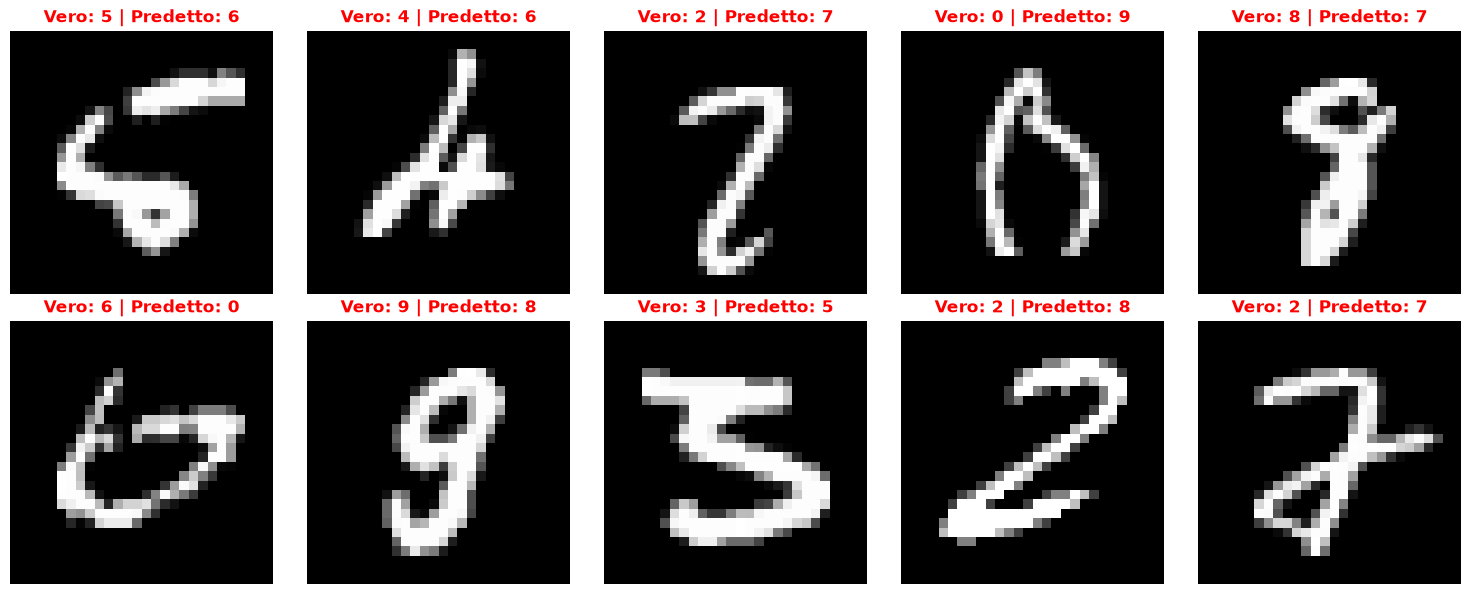

In [7]:
# Estrazione e analisi visiva delle "Misclassifications".
# Isola e decodifica i campioni del test set su cui la rete ha fallito la predizione.
# Permette un'indagine qualitativa per capire se l'errore deriva da limiti del classificatore 
# o dall'intrinseca ambiguità della grafia umana nel campione specifico.

# Rimuoviamo i primi 10000 zeri creati per errore dal blocco di inferenza
y_real = y[N_test:]
y_predicted = y_pred[N_test:]

# Trova gli indici in cui la predizione non corrisponde al valore reale
error_indices = np.where(y_real != y_predicted)[0]

print(f"Totale errori riscontrati: {len(error_indices)} su {len(y_real)} immagini di test.")

# Quante immagini errate vogliamo visualizzare
num_images_to_show = 10

# Crea un layout a griglia (2 righe, 5 colonne) per evitare sovrapposizioni
fig, axes = plt.subplots(2, 5, figsize=(15, 6))
axes = axes.flatten() # Appiattisce la matrice degli assi per iterarci facilmente

for i, idx in enumerate(error_indices[:num_images_to_show]):
    image, _ = mnist_test[idx]
    image_np = image.squeeze().numpy()
    
    axes[i].imshow(image_np, cmap='gray')
    # Titolo abbreviato per risparmiare spazio (V = Vero, P = Predetto)
    axes[i].set_title(f"Vero: {int(y_real[idx])} | Predetto: {int(y_predicted[idx])}", color='red', fontsize=12, fontweight='bold')
    axes[i].axis('off')

plt.tight_layout()
plt.show()